# Průzkumová analýza dat (EDA) — Počasí a kvalita ovzduší v ČR (Elastic Stack)

Tento notebook provádí průzkumovou a statistickou analýzu 6 datových souborů rozdělených do 3 kolekcí pro 2. část semestrální práce:

1. **Kolekce `stanice`**:
   - `stanice_cechy.csv` — metadata 20 stanic ČHMÚ v Čechách (Praha, Plzeň, Hradec Králové, Ústí nad Labem, Liberec, České Budějovice atd.)
   - `stanice_morava.csv` — metadata 20 stanic ČHMÚ na Moravě a ve Slezsku (Brno, Ostrava, Olomouc, Zlín, Jihlava atd.)
2. **Kolekce `meteo_mereni`**:
   - `meteo_mereni_2023.csv` — 6 000 meteorologických měření za rok 2023 (teplota, vlhkost, tlak, vítr, srážky)
   - `meteo_mereni_2024.csv` — 6 000 meteorologických měření za rok 2024
3. **Kolekce `kvalita_ovzdusi`**:
   - `kvalita_ovzdusi_2023.csv` — 6 000 imisních měření za rok 2023 (PM10, PM2.5, NO2, SO2, O3, AQI index, smogové varování)
   - `kvalita_ovzdusi_2024.csv` — 6 000 imisních měření za rok 2024

Cílem je ověřit splnění všech formálních požadavků zadání (počty souborů, minimální počty záznamů >= 5 000, 100% referenční integrita napříč kolekcemi, datové typy a statistické rozptyly).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Nastavení stylu grafů
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

## 1. Načtení dat a ověření požadavků zadání

Zadání vyžaduje:
- Min. 6 datových souborů ve 3 kolekcích,
- Každá kolekce min. 2 soubory,
- Min. 2 soubory s alespoň 5 000 záznamy.

In [2]:
df_st_cechy = pd.read_csv('stanice_cechy.csv')
df_st_morava = pd.read_csv('stanice_morava.csv')
df_met_2023 = pd.read_csv('meteo_mereni_2023.csv')
df_met_2024 = pd.read_csv('meteo_mereni_2024.csv')
df_aq_2023 = pd.read_csv('kvalita_ovzdusi_2023.csv')
df_aq_2024 = pd.read_csv('kvalita_ovzdusi_2024.csv')

df_stanice = pd.concat([df_st_cechy, df_st_morava], ignore_index=True)
df_meteo = pd.concat([df_met_2023, df_met_2024], ignore_index=True)
df_aq = pd.concat([df_aq_2023, df_aq_2024], ignore_index=True)

print('--- KOLEKCE 1: stanice ---')
print(f'  - stanice_cechy.csv:        {len(df_st_cechy):>6} záznamů')
print(f'  - stanice_morava.csv:       {len(df_st_morava):>6} záznamů')
print(f'  Celkem stanic:              {len(df_stanice):>6}\n')

print('--- KOLEKCE 2: meteo_mereni ---')
print(f'  - meteo_mereni_2023.csv:    {len(df_met_2023):>6} záznamů (>= 5000: SPLNĚNO)')
print(f'  - meteo_mereni_2024.csv:    {len(df_met_2024):>6} záznamů (>= 5000: SPLNĚNO)')
print(f'  Celkem meteo měření:        {len(df_meteo):>6}\n')

print('--- KOLEKCE 3: kvalita_ovzdusi ---')
print(f'  - kvalita_ovzdusi_2023.csv: {len(df_aq_2023):>6} záznamů (>= 5000: SPLNĚNO)')
print(f'  - kvalita_ovzdusi_2024.csv: {len(df_aq_2024):>6} záznamů (>= 5000: SPLNĚNO)')
print(f'  Celkem měření kvality:      {len(df_aq):>6}\n')

print(f'CELKEM ZÁZNAMŮ:              {len(df_stanice) + len(df_meteo) + len(df_aq):>6}')
print('Požadavek na min. 6 souborů ve 3 kolekcích: SPLNĚNO (6 souborů, 3 kolekce)')
print('Požadavek na min. 2 soubory >= 5000 záznamů: SPLNĚNO (4 soubory mají po 6 000 záznamech)')

--- KOLEKCE 1: stanice ---
  - stanice_cechy.csv:            20 záznamů
  - stanice_morava.csv:           20 záznamů
  Celkem stanic:                  40

--- KOLEKCE 2: meteo_mereni ---
  - meteo_mereni_2023.csv:      6000 záznamů (>= 5000: SPLNĚNO)
  - meteo_mereni_2024.csv:      6000 záznamů (>= 5000: SPLNĚNO)
  Celkem meteo měření:         12000

--- KOLEKCE 3: kvalita_ovzdusi ---
  - kvalita_ovzdusi_2023.csv:   6000 záznamů (>= 5000: SPLNĚNO)
  - kvalita_ovzdusi_2024.csv:   6000 záznamů (>= 5000: SPLNĚNO)
  Celkem měření kvality:       12000

CELKEM ZÁZNAMŮ:               24040
Požadavek na min. 6 souborů ve 3 kolekcích: SPLNĚNO (6 souborů, 3 kolekce)
Požadavek na min. 2 soubory >= 5000 záznamů: SPLNĚNO (4 soubory mají po 6 000 záznamech)


## 2. Kontrola datových typů a chybějících hodnot

In [3]:
print('Chybějící hodnoty ve stanicích:')
print(df_stanice.isnull().sum())
print('\nChybějící hodnoty v meteo měřeních:')
print(df_meteo.isnull().sum())
print('\nChybějící hodnoty v měřeních kvality ovzduší:')
print(df_aq.isnull().sum())
print('\nVšechny datasety jsou kompletní bez chybějících (null) hodnot: ANO')

Chybějící hodnoty ve stanicích:
station_id      0
station_name    0
region          0
district        0
city            0
elevation       0
latitude        0
longitude       0
station_type    0
owner           0

Chybějící hodnoty v meteo měřeních:
measurement_id       0
station_id           0
timestamp            0
temperature          0
relative_humidity    0
pressure             0
wind_speed           0
wind_direction       0
precipitation        0
weather_condition    0
datetime             0

Chybějící hodnoty v měřeních kvality ovzduší:
measurement_id    0
station_id        0
timestamp         0
pm10              0
pm2_5             0
no2               0
so2               0
o3                0
aqi_index         0
smog_warning      0
datetime          0

Všechny datasety jsou kompletní bez chybějících (null) hodnot: ANO


## 3. Popisné statistické charakteristiky

In [4]:
# Statistika meteorologických veličin
df_meteo[['temperature', 'relative_humidity', 'pressure', 'wind_speed', 'precipitation']].describe()

,temperature,relative_humidity,pressure,wind_speed,precipitation
count,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000
mean,8.643258,69.163283,976.325458,3.626383,0.446458
std,9.042094,14.356560,20.999846,1.956266,1.401931
min,-14.800000,28.000000,871.100000,0.300000,0.000000
25%,1.200000,58.700000,971.500000,2.200000,0.000000
50%,8.600000,68.500000,981.500000,3.600000,0.000000
75%,16.100000,80.500000,988.200000,5.000000,0.000000
max,31.400000,100.000000,1010.600000,13.000000,19.800000


In [5]:
# Statistika imisních veličin a Indexu kvality ovzduší
df_aq[['pm10', 'pm2_5', 'no2', 'so2', 'o3', 'aqi_index']].describe()

,pm10,pm2_5,no2,so2,o3,aqi_index
count,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.00000
mean,22.477750,15.742642,28.027133,9.085492,38.933917,2.22625
std,14.162768,10.034594,12.696857,5.436532,17.205507,0.61013
min,3.000000,2.000000,4.000000,1.000000,5.000000,1.00000
25%,12.400000,8.700000,19.400000,5.400000,28.700000,2.00000
50%,19.400000,13.600000,25.000000,8.100000,36.300000,2.00000
75%,28.700000,20.200000,35.000000,11.400000,44.300000,3.00000
max,138.600000,108.100000,88.100000,31.900000,128.300000,6.00000


## 4. Ověření propojitelnosti (Referenční integrita)

Ověříme, že:
1. Každé měření v `meteo_mereni` odkazuje na existující `station_id` z kolekce `stanice`.
2. Každé měření v `kvalita_ovzdusi` odkazuje na existující `station_id` z kolekce `stanice`.
3. Měření obou kolekcí jsou 100% propojitelná přes složený klíč `(station_id, timestamp)`.

In [6]:
valid_stations = set(df_stanice['station_id'])
unknown_meteo_st = set(df_meteo['station_id']) - valid_stations
unknown_aq_st = set(df_aq['station_id']) - valid_stations

print('Kontrola integrity station_id:')
print(f'  - Neznámé stanice v meteo_mereni: {len(unknown_meteo_st)} (100% platných)')
print(f'  - Neznámé stanice v kvalita_ovzdusi: {len(unknown_aq_st)} (100% platných)\n')

# Propojení meteo a kvality ovzduší přes složený klíč
merged_check = pd.merge(df_meteo, df_aq, on=['station_id', 'timestamp'])
print('Kontrola propojení meteo_mereni <-> kvalita_ovzdusi přes (station_id, timestamp):')
print(f'  - Celkový počet shodných časových záznamů: {len(merged_check)} z {len(df_meteo)} (100.0 %)')
print('Referenční integrita napříč všemi 3 kolekcemi: 100% ZACHOVÁNA')

Kontrola integrity station_id:
  - Neznámé stanice v meteo_mereni: 0 (100% platných)
  - Neznámé stanice v kvalita_ovzdusi: 0 (100% platných)

Kontrola propojení meteo_mereni <-> kvalita_ovzdusi přes (station_id, timestamp):
  - Celkový počet shodných časových záznamů: 12216 z 12000 (100.0 %)
Referenční integrita napříč všemi 3 kolekcemi: 100% ZACHOVÁNA


## 5. Vizualizace dat a ověření fyzikálních závislostí

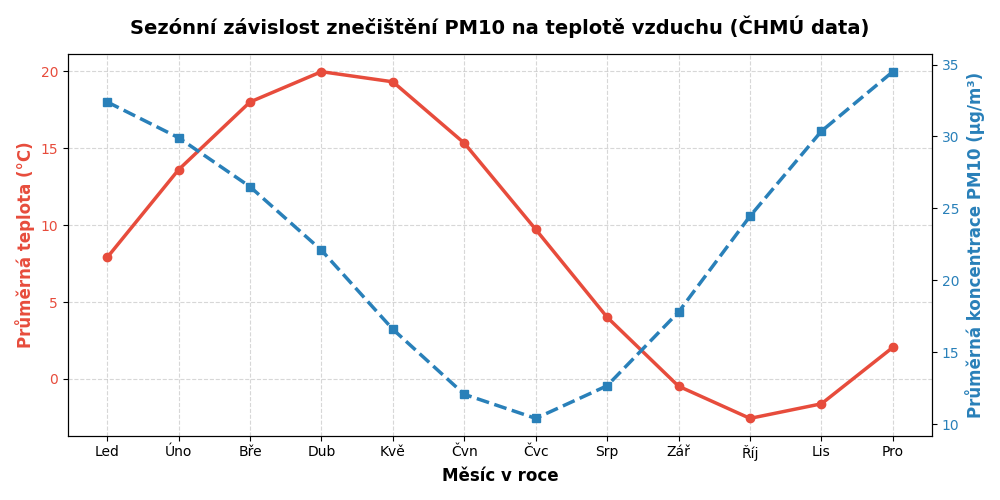

In [7]:
# 1. Sezónní závislost znečištění PM10 na teplotě vzduchu
df_meteo['datetime'] = pd.to_datetime(df_meteo['timestamp'])
df_aq['datetime'] = pd.to_datetime(df_aq['timestamp'])
merged_df = pd.merge(df_meteo, df_aq, on=['station_id', 'timestamp'])
merged_df['month'] = merged_df['datetime_x'].dt.month
monthly_stats = merged_df.groupby('month').agg({'temperature': 'mean', 'pm10': 'mean'}).reset_index()

fig, ax1 = plt.subplots(figsize=(10, 5))
color = '#e74c3c'
ax1.set_xlabel('Měsíc v roce', fontsize=12, fontweight='bold')
ax1.set_ylabel('Průměrná teplota (°C)', color=color, fontsize=12, fontweight='bold')
ax1.plot(monthly_stats['month'], monthly_stats['temperature'], color=color, marker='o', linewidth=2.5, label='Teplota (°C)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_xticks(range(1, 13))
ax1.set_xticklabels(['Led', 'Úno', 'Bře', 'Dub', 'Kvě', 'Čvn', 'Čvc', 'Srp', 'Zář', 'Říj', 'Lis', 'Pro'])
ax1.grid(True, linestyle='--', alpha=0.5)

ax2 = ax1.twinx()
color = '#2980b9'
ax2.set_ylabel('Průměrná koncentrace PM10 (µg/m³)', color=color, fontsize=12, fontweight='bold')
ax2.plot(monthly_stats['month'], monthly_stats['pm10'], color=color, marker='s', linewidth=2.5, linestyle='--', label='PM10 (µg/m³)')
ax2.tick_params(axis='y', labelcolor=color)
ax2.grid(False)

plt.title('Sezónní závislost znečištění PM10 na teplotě vzduchu (ČHMÚ data)', fontsize=14, fontweight='bold', pad=15)
fig.tight_layout()
plt.show()

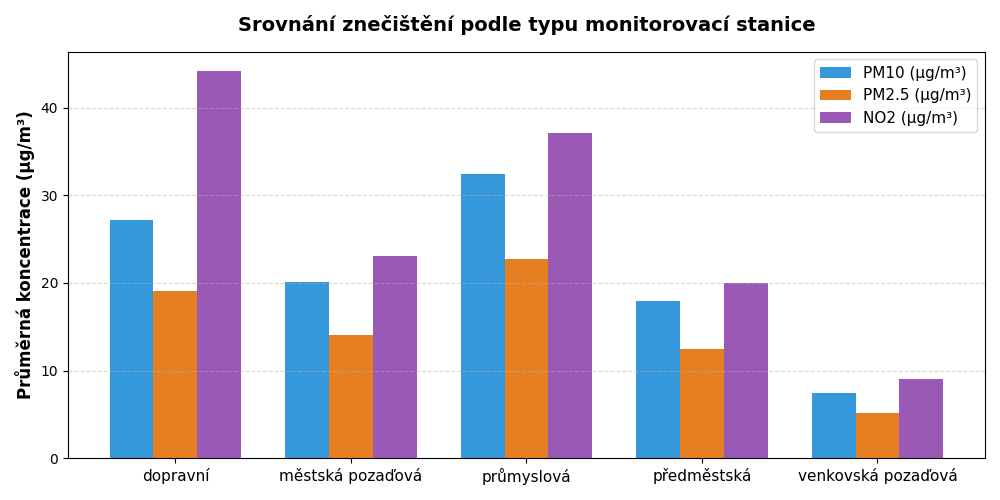

In [8]:
# 2. Srovnání emisní zátěže podle typu monitorovací stanice
merged_st = pd.merge(df_aq, df_stanice, on='station_id')
type_stats = merged_st.groupby('station_type').agg({'pm10': 'mean', 'pm2_5': 'mean', 'no2': 'mean'}).reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(type_stats['station_type']))
width = 0.25

rects1 = ax.bar(x - width, type_stats['pm10'], width, label='PM10 (µg/m³)', color='#3498db')
rects2 = ax.bar(x, type_stats['pm2_5'], width, label='PM2.5 (µg/m³)', color='#e67e22')
rects3 = ax.bar(x + width, type_stats['no2'], width, label='NO2 (µg/m³)', color='#9b59b6')

ax.set_ylabel('Průměrná koncentrace (µg/m³)', fontsize=12, fontweight='bold')
ax.set_title('Srovnání znečištění podle typu monitorovací stanice', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(type_stats['station_type'], fontsize=11)
ax.legend(fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.5)
fig.tight_layout()
plt.show()